# Cargas muertas sobre una viga de puente

Calculadora de las cargas lineales que recibe **una viga** a partir de la sección transversal del puente.
Todos los datos se ingresan en el **paso 1**; los pasos siguientes arman el dibujo elemento por elemento (el elemento nuevo aparece con **borde naranja**) y desarrollan cada carga.

| Paso | Elemento | Carga |
|---|---|---|
| 1 | **Datos** (todos) | $q_L$ (dato) |
| 2 | Losa | $q_{losa}$ |
| 3 | Aceras con alivianamiento | $q_{acera}$ |
| 4 | Carpeta asfáltica | $q_{asfalto}$ |
| 5 | Postes y pasamanos | $q_{parantes}$ |
| 6 | Valores para el programa principal | $q_D$ |

**Reparto:** losa y carpeta asfáltica por **área tributaria** de cada viga (ancho $S$); aceras, postes y pasamanos: peso total ÷ número de vigas.

> No incluye el peso propio de las vigas ($q_G$ asumido hasta definir la sección real).

**Unidades:** Sistema MKS especificadas en cada paso, modifique solo el **paso 1** y ejecute **Run All**.

In [1]:
import importlib
import os
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import sys
if 'Core' not in sys.path:
    sys.path.insert(0, 'Core')          # motores de cálculo (.py) en la carpeta Core
import cargas
importlib.reload(cargas)
from cargas import (Tablero, Poste, Pasamano, acera_rectangular, acera_poligono,
                    hueco_rect, hueco_circ, calcular_cargas, dibujar_tablero, dibujar_tributario,
                    dibujar_baranda, md_geometria, md_losa, md_acera, md_asfalto, md_parantes)

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}   # todas las figuras del mismo ancho


def mostrar(texto):
    display(Markdown(texto))


CARPETA_FIGURAS = 'Figuras'      # todas las figuras se guardan aquí (carpeta de trabajo)


def guardar(fig, nombre):
    '''Guarda la figura en la carpeta Figuras y la muestra.'''
    os.makedirs(CARPETA_FIGURAS, exist_ok=True)
    fig.savefig(os.path.join(CARPETA_FIGURAS, nombre), dpi=150, bbox_inches='tight')
    plt.show()


def paso(capas, resaltar):
    '''Dibuja el detalle acotado de la acera (y de la baranda, si está en las capas).'''
    guardar(dibujar_tablero(tablero, capas=capas, resaltar=resaltar, solo_detalle=True),
            f'cargas_detalle_{resaltar}.png')


def paso_tributario(capas, resaltar):
    '''Dibuja la franja tributaria de una viga (losa / asfalto).'''
    guardar(dibujar_tributario(tablero, capas=capas, resaltar=resaltar), f'cargas_tributaria_{resaltar}.png')

## 1. Datos Iniciales

**Acera** (coordenadas locales): $x = 0$ en el borde **exterior** del tablero, crece hacia la calzada; $y = 0$ sobre la cara superior de la losa. La acera del otro lado es simétrica.

- `acera_rectangular(ancho, alto, huecos)` o, si tiene bordillo, `acera_poligono([(x, y), ...], huecos)`
- Alivianamientos: `hueco_rect(x, y, b, h)` (esquina inferior exterior en $(x, y)$) o `hueco_circ(xc, yc, d)` (tubo); `huecos=[]` si no tiene.

In [2]:
# --- Generales ------------------------------------------------------------
l = 35.0             # luz del puente [m]
n_vigas = 3          # número de vigas
s = 350.0            # separación entre ejes de vigas = ancho tributario [cm]
voladizo = 125.0     # solo para el dibujo: el ancho del tablero no interviene en las cargas [cm]
gamma_c = 2400.0     # peso específico del hormigón [kg/m³]
gamma_asf = 2300.0   # peso específico del asfalto [kg/m³]
q_l = 1200.0         # carga viva [kg/m]  (DATO)

# --- Losa y carpeta asfáltica ---------------------------------------------
e_losa = 15.0        # espesor de la losa [cm]
e_asfalto = 3.0      # espesor de la carpeta asfáltica [cm]

# --- Aceras -----------------------------------------------------------------
n_aceras = 2                                              # número de aceras
acera = acera_rectangular(ancho=60, alto=20, huecos=[
    hueco_rect(x=10, y=5, b=40, h=10),
])

# --- Postes y pasamanos ---------------------------------------------------
n_lados_baranda = 2     # lados del puente con baranda
poste = Poste(
    b=10,               # ancho en el corte transversal [cm]
    c=10,               # espesor a lo largo del puente [cm]
    H=110,              # altura sobre la acera [cm]
    separacion=200,     # separación entre postes [cm]
    retiro=0,           # del borde exterior de la acera a la cara exterior del poste [cm]
)
pasamano = Pasamano(
    b=5, h=5,           # sección de cada barra [cm]
    alturas=(50, 100),  # altura del centro de cada barra sobre la acera [cm] (una por barra)
)

# --- Tablero y cargas (no modificar) ---------------------------------------
tablero = Tablero(L=l, n_vigas=n_vigas, S=s, voladizo=voladizo, e_losa=e_losa, e_asfalto=e_asfalto,
                  acera=acera, poste=poste, pasamano=pasamano, n_aceras=n_aceras,
                  n_lados_baranda=n_lados_baranda, gamma_c=gamma_c, gamma_asf=gamma_asf)
cargas_viga = calcular_cargas(tablero)

## 2. Losa

Por **área tributaria** de la viga (ancho $S$):

$$q_{losa} = e_{losa}\cdot S\cdot\gamma_c$$

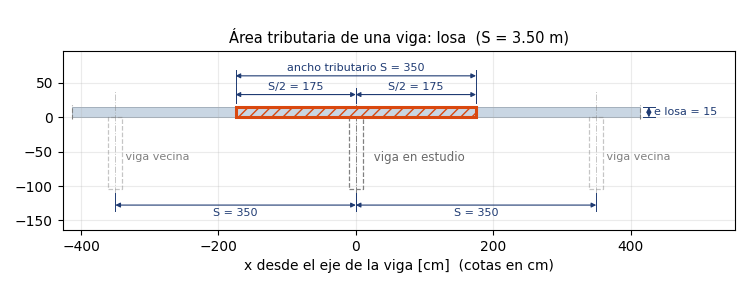


- Vigas: $n = 3$, separación $S = 3.50$ m → **ancho tributario de cada viga $= 3.50$ m**
- El ancho total del tablero no interviene en las cargas (en el dibujo es solo ilustrativo).

$$q_{losa} = e_{losa}\cdot S \cdot \gamma_c = (0.15)(3.50)(2,400) = \mathbf{1,260.00\ kg/m}$$


In [3]:
paso_tributario(capas=['losa'], resaltar='losa')
mostrar(md_geometria(cargas_viga) + md_losa(cargas_viga))

## 3. Aceras con alivianamiento

$$q_{acera} = \frac{n_{aceras}\cdot A_{neta}\cdot\gamma_c}{n_{vigas}}, \qquad A_{neta} = A_{bruta} - \sum A_{huecos}$$

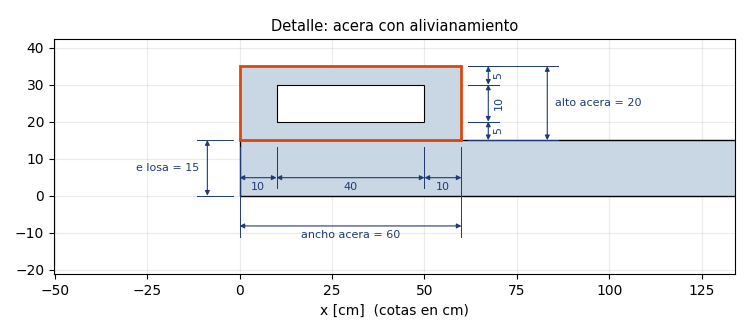


| Alivianamiento | x [cm] | y [cm] | Área [cm²] |
|---|---|---|---|
| 1 | 10 – 50 | 5 – 15 | 400.00 |

- $A_{bruta} = 1,200.00$ cm²
- $A_{huecos} = 400.00$ cm²
- $A_{neta} = 1,200.00 - 400.00 = 800.00$ cm² $= 0.0800$ m²

$$q_{acera} = \frac{n_{aceras}\cdot A_{neta}\cdot\gamma_c}{n_{vigas}} = \frac{(2)(0.0800)(2,400)}{3} = \mathbf{128.00\ kg/m}$$


In [4]:
paso(capas=['losa', 'aceras'], resaltar='aceras')
mostrar(md_acera(cargas_viga))

## 4. Carpeta asfáltica

Por **área tributaria** de la viga (ancho $S$):

$$q_{asfalto} = e_{asf}\cdot S\cdot\gamma_{asf}$$

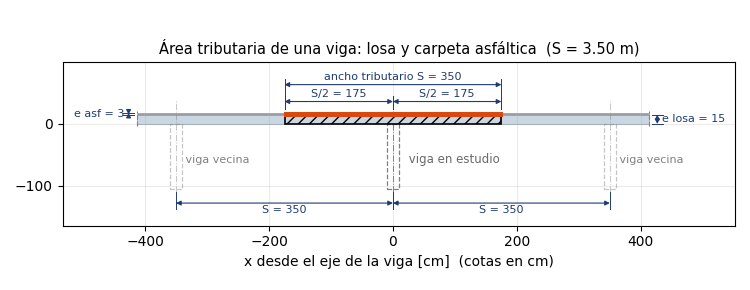


$$q_{asf} = e_{asf}\cdot S \cdot \gamma_{asf} = (0.03)(3.50)(2,300) = \mathbf{241.50\ kg/m}$$


In [5]:
paso_tributario(capas=['losa', 'asfalto'], resaltar='asfalto')
mostrar(md_asfalto(cargas_viga))

## 5. Postes y pasamanos

Se cuentan los postes que entran en la longitud del puente, **incluidos el inicial y el final**, y se suma el peso de las barandas horizontales a lo largo de $L$. El peso total se divide para $L$ y se reparte entre las vigas.

$$N = \left\lceil \frac{L}{s_{postes}} \right\rceil + 1 \qquad
q_{parantes} = \frac{n_{lados}\,\left(N\,V_{poste} + n_b\,L\,A_b\right)\gamma_c}{L\cdot n_{vigas}}$$

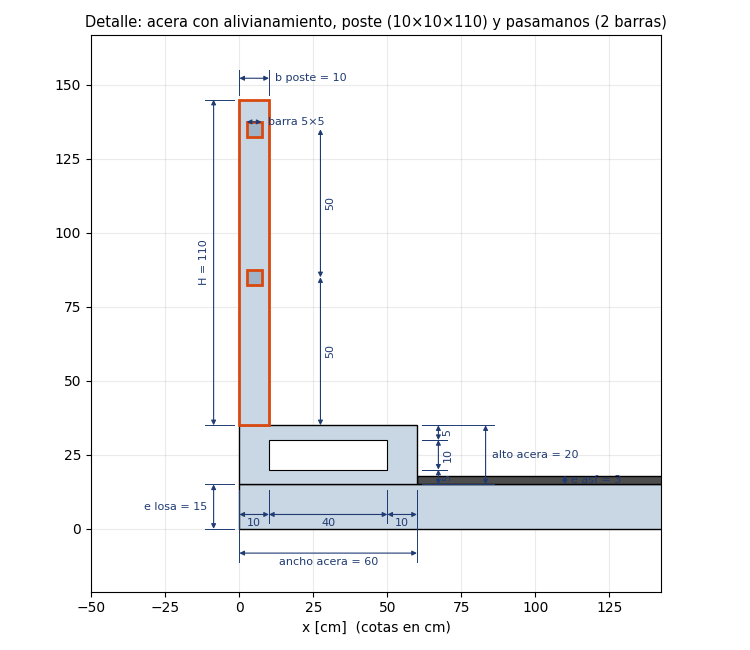

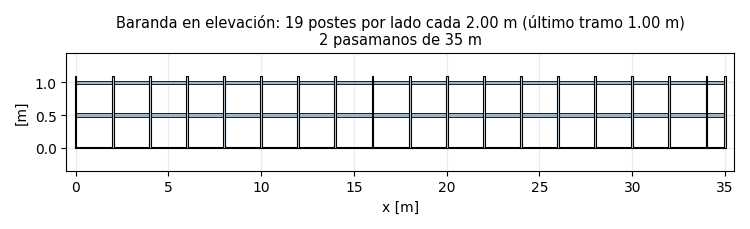


**a) Postes** — sección $(0.10 \times 0.10)$ m, altura $1.10$ m, cada $s = 2.00$ m

- Número de postes por lado (incluye el inicial y el final):

$$N = \left\lceil \frac{L}{s} \right\rceil + 1 = \left\lceil \frac{35}{2.00} \right\rceil + 1 = 19$$

- Último tramo entre postes $= 1.00$ m
- Volumen de un poste: $V = (0.10)(0.10)(1.10) = 0.0110$ m³
- Peso de los postes de un lado: $W_{postes} = N\,V\,\gamma_c = (19)(0.0110)(2,400) = 501.60$ kg

**b) Pasamanos** — 2 barras de $(0.05 \times 0.05)$ m a lo largo de $L$

- Área de una barra: $A_b = (0.05)(0.05) = 0.0025$ m²
- Peso de los pasamanos de un lado: $W_{barandas} = n_b\,L\,A_b\,\gamma_c = (2)(35)(0.0025)(2,400) = 420.00$ kg

**c) Carga por viga**

$$q_{parantes} = \frac{n_{lados}\,(W_{postes} + W_{barandas})}{L\cdot n_{vigas}} = \frac{2\,(501.60 + 420.00)}{(35)(3)} = \mathbf{17.55\ kg/m}$$


In [6]:
paso(capas=['losa', 'aceras', 'asfalto', 'baranda'], resaltar='baranda')
guardar(dibujar_baranda(cargas_viga), 'cargas_baranda_elevacion.png')
mostrar(md_parantes(cargas_viga))

## 6. Valores para el programa principal

Las cargas se guardan en **`Datos/cargas.json`**, que el cuaderno de diseño (`Diseno_Viga_Presforzada.ipynb`) lee automáticamente con `usar_json = True`. También se pueden pasar a mano:

```python
datos = Datos(L=..., fc=..., perdidas=..., d2=..., q_L=q_l, **cargas_viga.como_dict())
```

In [7]:
print('Valores para el programa principal:')
for k, v in cargas_viga.como_dict().items():
    print(f'  {k:<11}= {v:>10,.2f} kg/m')
print(f'  {"q_D":<11}= {cargas_viga.qD:>10,.2f} kg/m')
print(f'  {"q_L":<11}= {q_l:>10,.2f} kg/m  (dato)')

ruta = cargas_viga.guardar_json(q_l, 'Datos/cargas.json')
print()
print(f'Guardado en {ruta} (lo lee el cuaderno de diseño).')

Valores para el programa principal:
  q_losa     =   1,260.00 kg/m
  q_acera    =     128.00 kg/m
  q_parantes =      17.55 kg/m
  q_asfalto  =     241.50 kg/m
  q_D        =   1,647.05 kg/m
  q_L        =   1,200.00 kg/m  (dato)

Guardado en Datos/cargas.json (lo lee el cuaderno de diseño).
